In [1]:
import pandas as pd

df=pd.read_csv("D:/imdb-sentiment-analysis/data/IMDB Dataset.csv")
print("Data shape:", df.shape)
print("columns:", df.columns)

print(df.head())


Data shape: (50000, 2)
columns: Index(['review', 'sentiment'], dtype='str')
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [2]:
print(df['sentiment'].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [3]:
print("Number of null values:", df.isnull().sum())

print("Number of duplicated rows:", df.duplicated().sum())
print("Number of duplicated reviews:", df.duplicated(subset="review").sum())


print("Conflicting labels:",(df.groupby("review")["sentiment"].nunique() > 1).sum())

Number of null values: review       0
sentiment    0
dtype: int64
Number of duplicated rows: 418
Number of duplicated reviews: 418
Conflicting labels: 0


In [4]:
df_clean=df.drop_duplicates().reset_index(drop=True)

print("Cleaned data shape:", df_clean.shape)
print("orginal data shape:", df.shape)
print("Remaining duplicated :", df_clean.duplicated(subset="review").sum())

Cleaned data shape: (49582, 2)
orginal data shape: (50000, 2)
Remaining duplicated : 0


In [5]:
df_clean["review_length"]=df_clean["review"].str.split().str.len()
print("Review length statistics:")
print(df_clean["review_length"].describe())


Review length statistics:
count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: review_length, dtype: float64


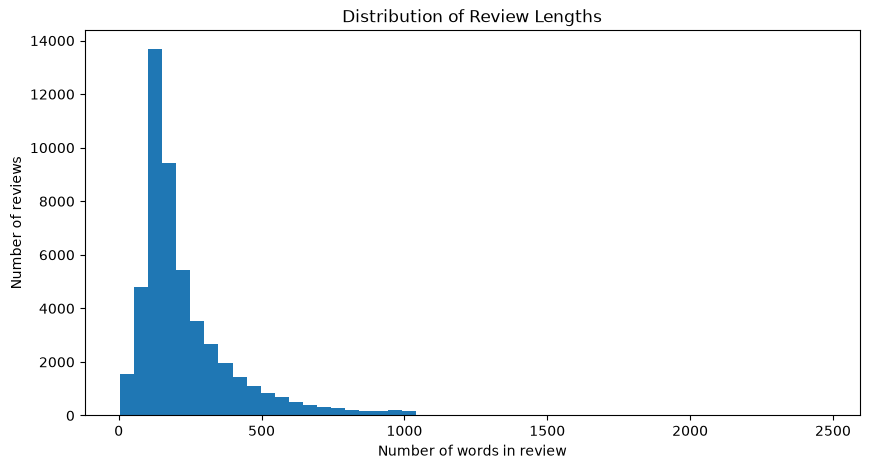

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.hist(df_clean["review_length"], bins=50)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of words in review")
plt.ylabel("Number of reviews")

plt.show()

In [7]:
df_clean.groupby("sentiment")["review_length"].agg(["mean", "median", "max","count"])

,mean,median,max,count
sentiment,,,,
negative,229.596607,174.0,1522,24698
positive,233.090620,172.0,2470,24884


Exploration of data summary:
the orginal dataset size is 50000
we not have any missing value

in our dataset we have two columns (review,sentiment)
we have 25000 positive review and 25000 negative review 
we have 418 duplicate 
after removing duplicates we have  49582 clean review 
the mean of review length is 231
after clean duplicate we have  24698 negative review 
after clean duplicate we have  24884 postive review 
